# SOD4SB demo: detecting tiny birds in 4K frames

This notebook loads the two released detectors, runs the final configuration on one validation frame, visualises the result and reproduces the main numbers of the paper.

**Final configuration** — YOLOv8-M trained with slicing, predicted on the full frame and on its mirror, plus GFL R50-FPN; the three box sets are merged by one weighted boxes fusion (IoU 0.55, weights 1:1:1).

Before running: download `yolov8m_slicing_e30.pt` and `gfl_r50_fpn_ep38.pth` from the GitHub Release into `weights/`, and place the MVA 2023 SOD4SB data as described in the README.

In [1]:
import json, os, subprocess, sys, time, warnings
warnings.filterwarnings('ignore')
from pathlib import Path
import cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import model

DATA = Path(os.environ.get('SOD4SB_DATA', '.'))          # folder that contains mva2023_sod4bird_train/
ANN = DATA/'data/mva_audited_v1/annotations/split_val_coco.json'
IMAGES = DATA/'mva2023_sod4bird_train/images'
ann = json.loads(ANN.read_text(encoding='utf-8'))
print(f"validation split: {len(ann['images'])} frames, {len(ann['annotations'])} birds")

validation split: 879 frames, 2864 birds


## 1. Load the two detectors

In [2]:
det = model.Detector('weights/yolov8m_slicing_e30.pt', 'weights/gfl_r50_fpn_ep38.pth')
count = lambda m: sum(p.numel() for p in m.parameters()) / 1e6
print(f'YOLOv8-M: {count(det.yolo):.1f} M parameters | GFL R50-FPN: {count(det.gfl):.1f} M parameters')

Overriding model.yaml nc=80 with nc=1


YOLOv8-M: 25.9 M parameters | GFL R50-FPN: 32.3 M parameters


## 2. Run the final configuration on one validation frame

Most frames contain only a few birds (median 2). For a clearer picture we take the **first validation frame with 8 annotated birds** (chosen by bird count, not by result) and run each source separately, then the fusion.

Each source is read at its own operating point, the score threshold with the best F1 on the validation split (fused scores are averaged over three sources, so they are lower). AP50 on the frame does not depend on a threshold.

In [3]:
gt_by_img = {}
for a in ann['annotations']:
    x, y, w, h = a['bbox']; gt_by_img.setdefault(a['image_id'], []).append([x, y, x + w, y + h])
image_id = next(im['id'] for im in ann['images'] if len(gt_by_img.get(im['id'], [])) == 8)
info = next(im for im in ann['images'] if im['id'] == image_id)
path, gt = IMAGES/info['file_name'], np.array(gt_by_img[image_id])
img = cv2.imread(str(path))

t = time.time(); plain, flipped = model.predict_yolo(det.yolo, img); t_yolo = time.time() - t
t = time.time(); gfl = model.predict_gfl(det.gfl, path); t_gfl = time.time() - t
fused = model.fuse([gfl, plain, flipped])

from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
import contextlib, io
def ap50(boxes):
    res = [dict(image_id=image_id, category_id=0, bbox=[float(a), float(b), float(c - a), float(d - b)], score=float(s)) for a, b, c, d, s in boxes]
    with contextlib.redirect_stdout(io.StringIO()):
        g = COCO(str(ANN)); e = COCOeval(g, g.loadRes(res), 'bbox'); e.params.imgIds = [image_id]; e.params.maxDets = [1, 10, 100]
        e.evaluate(); e.accumulate(); e.summarize()
    return round(100 * e.stats[1], 1)

def matched(boxes, thr):
    b = boxes[boxes[:, 4] >= thr]
    if not len(b): return 0
    ix = np.clip(np.minimum(b[:, None, 2], gt[None, :, 2]) - np.maximum(b[:, None, 0], gt[None, :, 0]), 0, None)
    iy = np.clip(np.minimum(b[:, None, 3], gt[None, :, 3]) - np.maximum(b[:, None, 1], gt[None, :, 1]), 0, None)
    inter = ix * iy; area = lambda z: (z[:, 2] - z[:, 0]) * (z[:, 3] - z[:, 1])
    iou = inter / (area(b)[:, None] + area(gt)[None, :] - inter)
    return int((iou.max(0) >= 0.5).sum())

# best-F1 score thresholds on the validation split (results/error_analysis/*.json)
rows = [('YOLO, full frame', plain, 0.375), ('YOLO, mirrored frame', flipped, 0.375), ('GFL', gfl, 0.40),
        ('WBF of the three (final)', fused, 0.25)]
pd.DataFrame([(n, thr, ap50(b), int((b[:, 4] >= thr).sum()), matched(b, thr)) for n, b, thr in rows],
             columns=['source', 'threshold', 'AP50 on this frame', 'boxes kept', f'birds found (of {len(gt)})'])

,source,threshold,AP50 on this frame,boxes kept,birds found (of 8)
0,"YOLO, full frame",0.375,77.7,8,5
1,"YOLO, mirrored frame",0.375,80.9,8,5
2,GFL,0.400,52.4,11,4
3,WBF of the three (final),0.250,63.5,8,4


In [4]:
print(f'frame {img.shape[1]}x{img.shape[0]}: YOLO (2 views) {t_yolo*1000:.0f} ms, GFL {t_gfl*1000:.0f} ms')

frame 3840x2160: YOLO (2 views) 1055 ms, GFL 712 ms


**Reading the table.** One frame is a very small sample: here the fused boxes score lower than YOLO alone, mostly because several boxes are shifted by a few pixels and miss the IoU 0.5 criterion (see the crops below). Over the 879 validation frames the fusion is clearly better (AP50 84.5% vs 81.0% for YOLO with flip TTA, Section 4), and the held-out halves agree (84.1% / 85.0%).

## 3. Visualise

Crops around each annotated bird, enlarged 3×. Green: ground truth. Red: final prediction at its operating point (score ≥ 0.25).

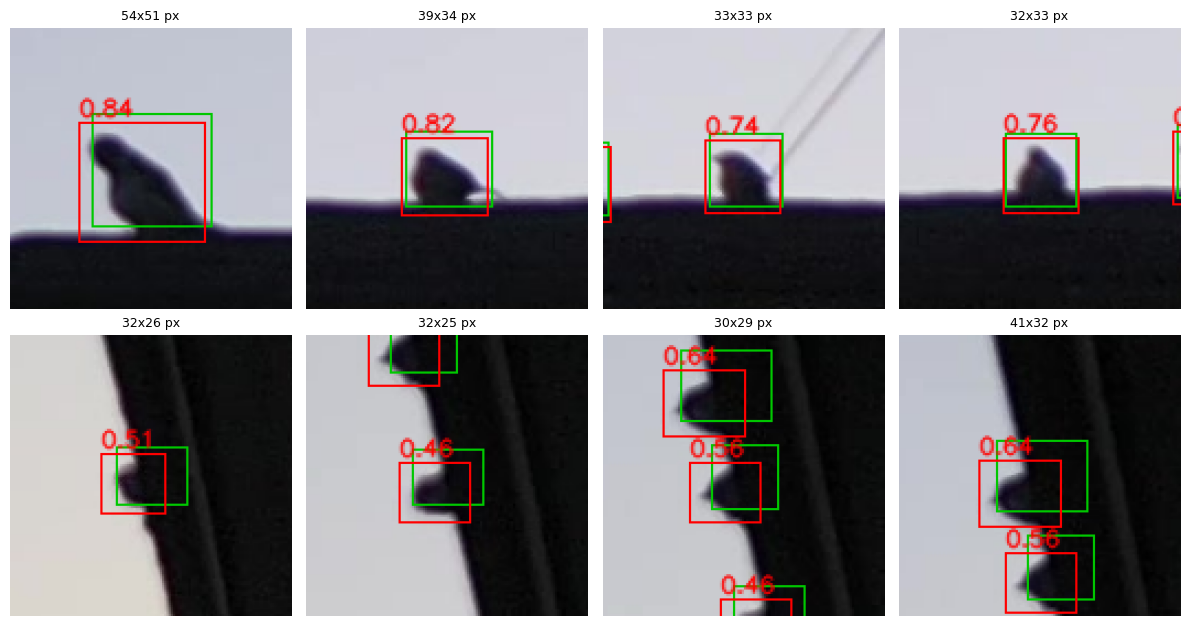

In [5]:
vis = model.draw(img, fused, gt=gt, thr=0.25)
n = min(8, len(gt)); fig, axes = plt.subplots(2, 4, figsize=(12, 6.4))
for ax, (x1, y1, x2, y2) in zip(axes.flat, gt[:n]):
    cx, cy, s = int((x1 + x2) / 2), int((y1 + y2) / 2), 64
    crop = vis[max(cy - s, 0):cy + s, max(cx - s, 0):cx + s]
    ax.imshow(cv2.cvtColor(cv2.resize(crop, None, fx=3, fy=3, interpolation=cv2.INTER_NEAREST), cv2.COLOR_BGR2RGB))
    ax.set_title(f'{int(x2 - x1)}x{int(y2 - y1)} px', fontsize=9)
for ax in axes.flat: ax.axis('off')
plt.tight_layout(); plt.show()

## 4. Results of the paper (from the saved JSON files)

All numbers: audited validation split, COCO maxDets 100, %.

In [6]:
R = Path('results')
train = {k: json.loads((R/f'training/{k}/epoch_30_metrics.json').read_text()) for k in
         ['baseline_m_e30', 'augmentation_m_e30', 'copy_paste_m_e30', 'slicing_m_e30']}
pd.DataFrame([(k.replace('_e30', ''), 100*v['AP50'], 100*v['AP75'], 100*v['AR100']) for k, v in train.items()],
             columns=['YOLOv8-M training method (epoch 30)', 'AP50', 'AP75', 'AR100']).round(1)

,YOLOv8-M training method (epoch 30),AP50,AP75,AR100
0,baseline_m,70.2,25.5,43.9
1,augmentation_m,70.0,25.5,43.8
2,copy_paste_m,66.9,23.2,42.2
3,slicing_m,79.3,38.8,50.0


In [7]:
inf = {n: json.loads((R/f'inference/{f}.json').read_text()) for n, f in [
    ('full frame', 'slicing_m_e30_full'), ('flip TTA (NMS)', 'slicing_m_e30_tta'),
    ('SAHI x1.5', 'slicing_m_e30_sahi_z1.5'), ('SAHI x1.0', 'slicing_m_e30_sahi_z1')]}
ens = json.loads((R/'ensemble/gfl+plain+flip.json').read_text())['rules']['wbf_i0.55_w1']
rows = [(n, 100*v['AP50'], 100*v['AP75'], round(v['ms_per_image'])) for n, v in inf.items()]
rows.append(('flip TTA + GFL, one WBF (final)', 100*ens['AP50'], 100*ens['AP75'], None))
pd.DataFrame(rows, columns=['inference on the slicing model', 'AP50', 'AP75', 'ms / frame']).round(1)

,inference on the slicing model,AP50,AP75,ms / frame
0,full frame,79.3,38.8,337.0
1,flip TTA (NMS),79.9,38.5,709.0
2,SAHI x1.5,67.5,28.7,1748.0
3,SAHI x1.0,78.5,38.0,963.0
4,"flip TTA + GFL, one WBF (final)",84.5,45.8,NaN


## 4b. Split A / split B (held-out halves of validation)

Choosing a merging rule on the same 879 frames on which it is scored would flatter it. The validation frames are
therefore split by their position in the annotation file: **split A** = odd positions, **split B** = even positions.
A rule is chosen on one split and reported on the other (Section 5.2 of the paper). The numbers below are read from the
saved result files of `scripts/merge_tune.py` (flip TTA) and `scripts/ensemble_wbf.py` (ensemble with GFL).


In [8]:
SPLIT_A = [im['id'] for im in ann['images']][1::2]     # odd positions
SPLIT_B = [im['id'] for im in ann['images']][0::2]     # even positions
birds = lambda ids: sum(1 for a in ann['annotations'] if a['image_id'] in set(ids))
print(f'split A: {len(SPLIT_A)} frames, {birds(SPLIT_A)} birds | split B: {len(SPLIT_B)} frames, {birds(SPLIT_B)} birds')

ens = json.loads(Path('results/ensemble/gfl+plain+flip.json').read_text(encoding='utf-8'))
tta = json.loads(Path('results/inference/slicing_m_e30_tta_merge_tune.json').read_text(encoding='utf-8'))
names = {'single_0': 'GFL alone', 'single_1': 'YOLO alone', 'single_2': 'YOLO flipped alone'}
rows = [dict(rule=names.get(k, k), AP50_all=v['AP50'], AP50_A=v['AP50_odd'], AP50_B=v['AP50_even']) for k, v in ens['rules'].items()]
display((pd.DataFrame(rows).set_index('rule') * 100).round(1).sort_values('AP50_all', ascending=False))

h, t = ens['held_out'], tta['held_out']
print('Held-out check (choose on one split, report on the other), AP50 %:')
display(pd.DataFrame([
    dict(method='flip TTA (YOLO)',     chosen_on_A=t['chosen_on_odd'], score_on_B=100*t['its_AP50_on_even'],
         chosen_on_B=t['chosen_on_even'], score_on_A=100*t['its_AP50_on_odd']),
    dict(method='ensemble YOLO x2 + GFL', chosen_on_A=h['chosen_on_odd'], score_on_B=100*h['its_AP50_on_even'],
         chosen_on_B=h['chosen_on_even'], score_on_A=100*h['its_AP50_on_odd']),
]).set_index('method').round(1))


split A: 439 frames, 1534 birds | split B: 440 frames, 1330 birds


,AP50_all,AP50_A,AP50_B
rule,,,
wbf_i0.5_w1,84.5,84.2,84.8
wbf_i0.55_w1,84.5,84.1,85.0
wbf_i0.6_w1,84.4,84.2,84.8
wbf_i0.5_w2,84.2,83.9,84.7
wbf_i0.55_w2,84.2,83.8,84.7
wbf_i0.6_w2,84.2,84.0,84.5
wbf_i0.5_w3,83.8,83.4,84.2
wbf_i0.55_w3,83.7,83.4,84.1
wbf_i0.6_w3,83.7,83.5,83.9


Held-out check (choose on one split, report on the other), AP50 %:


,chosen_on_A,score_on_B,chosen_on_B,score_on_A
method,,,,
flip TTA (YOLO),wbf,81.4,wbf,80.7
ensemble YOLO x2 + GFL,wbf_i0.5_w1,84.8,wbf_i0.55_w1,84.1


## 5. Evaluate on the validation split

`main.py` runs the final configuration frame by frame and reports COCO metrics. The full split (879 frames) takes about 30 minutes on an 8 GB laptop GPU; here we check the first 20 frames.

In [9]:
out = subprocess.check_output([sys.executable, 'main.py', '--ann', str(ANN), '--images', str(IMAGES), '--limit', '20',
                               '--out', 'results/val_predictions_first20.json'],
                              text=True, stderr=subprocess.DEVNULL, stdin=subprocess.DEVNULL)
print('\n'.join(out.strip().splitlines()[-2:]))

3491 boxes on 20 images -> results/val_predictions_first20.json
AP50 93.5%  AP75 55.8%  AR100 60.2%


## 6. Public test set

The public test split (9,699 frames) has **no released labels**, so it cannot be scored here: it was used only once,
to produce the submission file with the configuration chosen on validation (WBF of GFL + YOLO + flipped YOLO).
Below: the summary of that submission, then the same detector on one test frame. Many frames contain no bird the
detector is confident about (frame 1 has none), so we walk through the frames in order and show the **first one with
at least 5 predicted birds**. Red boxes are predictions with fused score >= 0.25, the best-F1 operating point of the
fusion on validation. Without labels we cannot tell which of them are correct.


In [10]:
TEST = DATA/'mva2023_sod4bird_pub_test'
TEST_IMAGES = TEST/'images'
test_ann = json.loads((TEST/'annotations/public_test_coco_empty_ann.json').read_text(encoding='utf-8'))
info = json.loads(Path('results/submission/final_ensemble_test_info.json').read_text(encoding='utf-8'))
print(f"public test split: {len(test_ann['images'])} frames, {len(test_ann.get('annotations', []))} released labels")
print(f"submission: {info['boxes']:,} boxes on {info['images']:,} frames ({info['boxes']/info['images']:.0f} per frame, "
      f"score >= 0.001, at most 300 per source); rule: {info['rule']}; validation AP50 of this rule: {info['val_AP50_of_rule']:.1%}")


public test split: 9699 frames, 0 released labels
submission: 1,782,137 boxes on 9,699 frames (184 per frame, score >= 0.001, at most 300 per source); rule: WBF IoU 0.55, weights 1:1:1; validation AP50 of this rule: 84.5%


00001.jpg: 0 birds predicted at score >= 0.25 (1020 ms, 3 sources + fusion)


00002.jpg: 0 birds predicted at score >= 0.25 (1033 ms, 3 sources + fusion)


00003.jpg: 1 birds predicted at score >= 0.25 (1021 ms, 3 sources + fusion)


00004.jpg: 2 birds predicted at score >= 0.25 (1035 ms, 3 sources + fusion)


00005.jpg: 2 birds predicted at score >= 0.25 (997 ms, 3 sources + fusion)


00006.jpg: 1 birds predicted at score >= 0.25 (1011 ms, 3 sources + fusion)


... (2 outputs left out)

00009.jpg: 0 birds predicted at score >= 0.25 (961 ms, 3 sources + fusion)


00010.jpg: 1 birds predicted at score >= 0.25 (971 ms, 3 sources + fusion)


00011.jpg: 0 birds predicted at score >= 0.25 (976 ms, 3 sources + fusion)


00012.jpg: 8 birds predicted at score >= 0.25 (1011 ms, 3 sources + fusion)


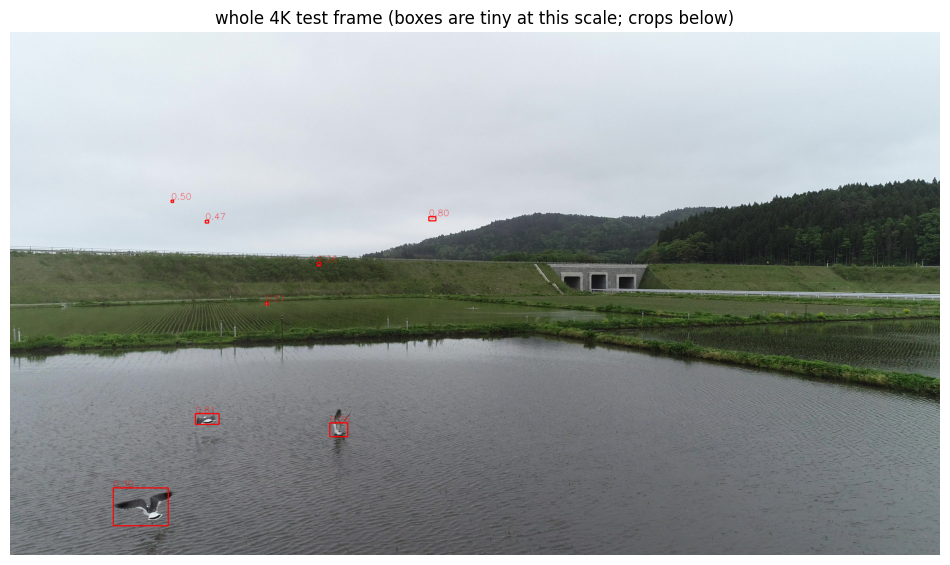

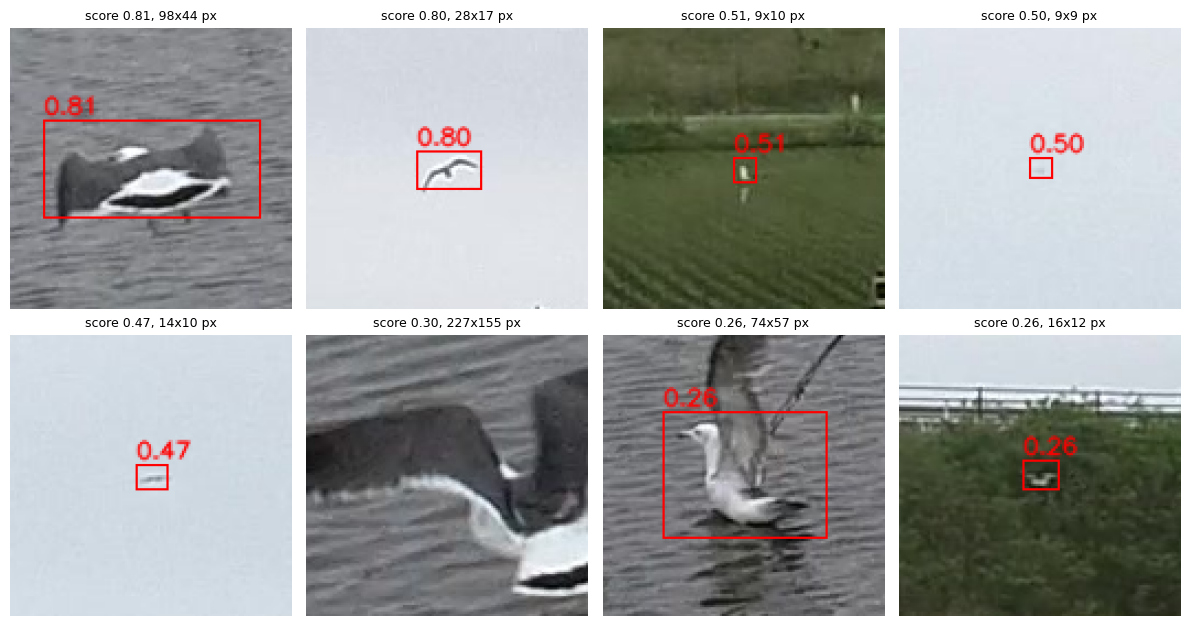

In [11]:
for test_info in test_ann['images']:            # first frame (in file order) with >= 5 predicted birds
    test_path = TEST_IMAGES/test_info['file_name']
    test_img = cv2.imread(str(test_path))
    t = time.time(); t_plain, t_flip = model.predict_yolo(det.yolo, test_img); t_gfl_boxes = model.predict_gfl(det.gfl, test_path)
    test_fused = model.fuse([t_gfl_boxes, t_plain, t_flip]); dt = time.time() - t
    keep = test_fused[test_fused[:, 4] >= 0.25]
    print(f"{test_info['file_name']}: {len(keep)} birds predicted at score >= 0.25 ({dt*1000:.0f} ms, 3 sources + fusion)")
    if len(keep) >= 5: break

test_vis = model.draw(test_img, test_fused, thr=0.25, thickness=4, font_scale=1.2)
plt.figure(figsize=(12, 6.8)); plt.imshow(cv2.cvtColor(test_vis, cv2.COLOR_BGR2RGB)); plt.axis('off')
plt.title('whole 4K test frame (boxes are tiny at this scale; crops below)'); plt.show()

crop_vis = model.draw(test_img, test_fused, thr=0.25)
n = min(8, len(keep))
if n:
    fig, axes = plt.subplots(2, 4, figsize=(12, 6.4))
    for ax, (x1, y1, x2, y2, s) in zip(axes.flat, keep[:n]):
        cx, cy, r = int((x1 + x2) / 2), int((y1 + y2) / 2), 64
        crop = crop_vis[max(cy - r, 0):cy + r, max(cx - r, 0):cx + r]
        ax.imshow(cv2.cvtColor(cv2.resize(crop, None, fx=3, fy=3, interpolation=cv2.INTER_NEAREST), cv2.COLOR_BGR2RGB))
        ax.set_title(f'score {s:.2f}, {int(x2 - x1)}x{int(y2 - y1)} px', fontsize=9)
    for ax in axes.flat: ax.axis('off')
    plt.tight_layout(); plt.show()
